<a href="https://colab.research.google.com/github/ShenlyR/Analisis-Numerik/blob/main/Hitung_Lambung_Perahu_Revisi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Nama:** Shenly Lestari Riada

**NPM:** 25083010019

**Kelas:** A

**Link Github:** https://github.com/ShenlyR/Analisis-Numerik.git

**Import Library**

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import simpson
from PIL import Image

**Model Sketsa Perahu**

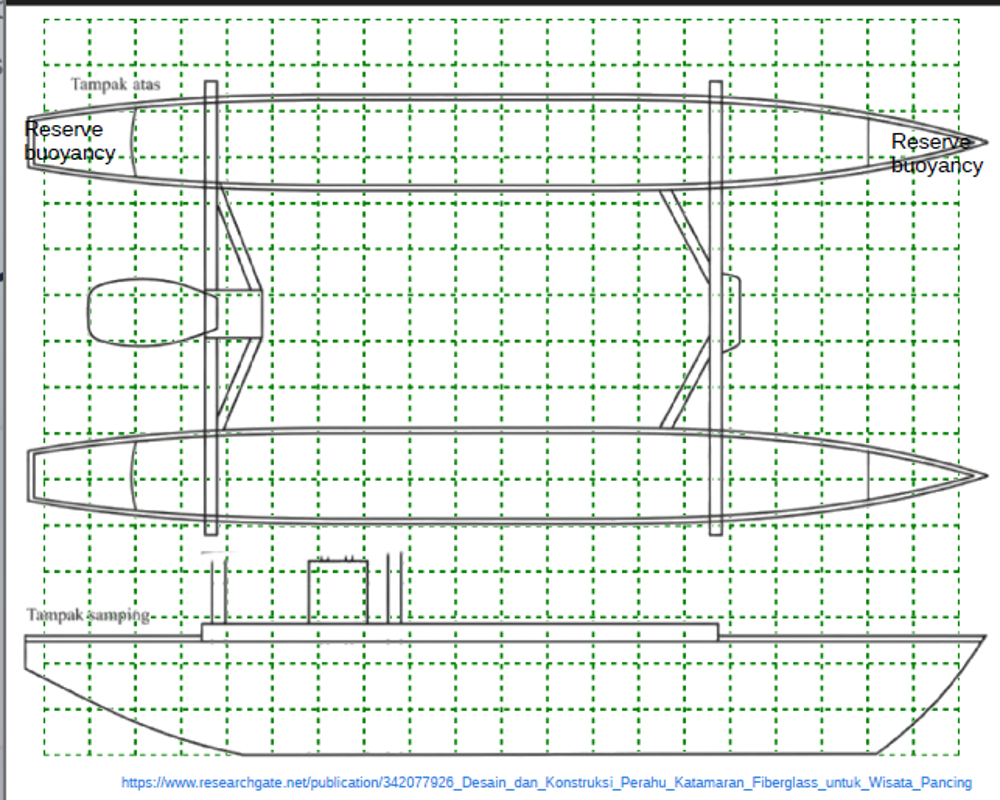

In [24]:
img = Image.open('/content/sketsa perahu.png')
img = img.resize((1000, 800))
display(img)

**Menentukan Jarak Antar Titik**
*   Ukuran satu dash-kosong yaitu 45 cm

1. Rumus Konversi satuan centimeter (cm) ke meter (m)
$$
h = \frac{45}{100} = 0{,}45 \text{ m}
$$


2. Rumus jarak setiap titik
$$
x_i = (i - 2)h
$$

Keterangan:
- $h$ = jarak antar-titik (m)
- $x_i$ = jarak titik ke-$i$ dari titik awal (m)
- $i$ = nomor titik grid






In [2]:
ukuran_kotak_cm = 45
ukuran_kotak_m = ukuran_kotak_cm / 100
h = ukuran_kotak_m

# index station
kotak = np.arange(2, 19)
jarak_m = (kotak - 2) * h

# array dalam meter
lebar = np.array([0.7840, 0.8662, 0.9231, 0.9484, 0.9610, 0.9610, 0.9610, 0.9610, 0.9610,
                  0.9610, 0.9610, 0.9610, 0.9484, 0.8978, 0.8346, 0.7334, 0.5943])

tinggi = np.array([0.8534, 1.0178, 1.1443, 1.1796, 1.1796, 1.1796, 1.1796, 1.1796, 1.1796,
                   1.1796, 1.1759, 1.1759, 1.1759, 1.1759, 1.1759, 1.1759, 1.1759])

**Visualisasi Interval Perahu**

Grafik menunjukkan lebar dan tinggi lambung pada 17 titik dengan jarak $h$ = 0.45m, sehingga panjang lambung 7.20 m dan jumlah interval 16.

Pada tampak atas, setengah lebar naik dari 0.39 m ke maksimum sekitar 0.48 m (titik ke 4-11), kemudian mengecil sekitar 0.30 m di titik 16.

Pada Tampak samping, tinggi naik dari 0.8534 m ke maksimum 1.1796 m di titik 3, kemudian hampir seluruh nilainya tetap sampai titik 16.
Titik interval tinggi hanya diambil pada bagian lambung diantara kedua sekat, sehingga volume reserve buoyancy tidak dihitung.


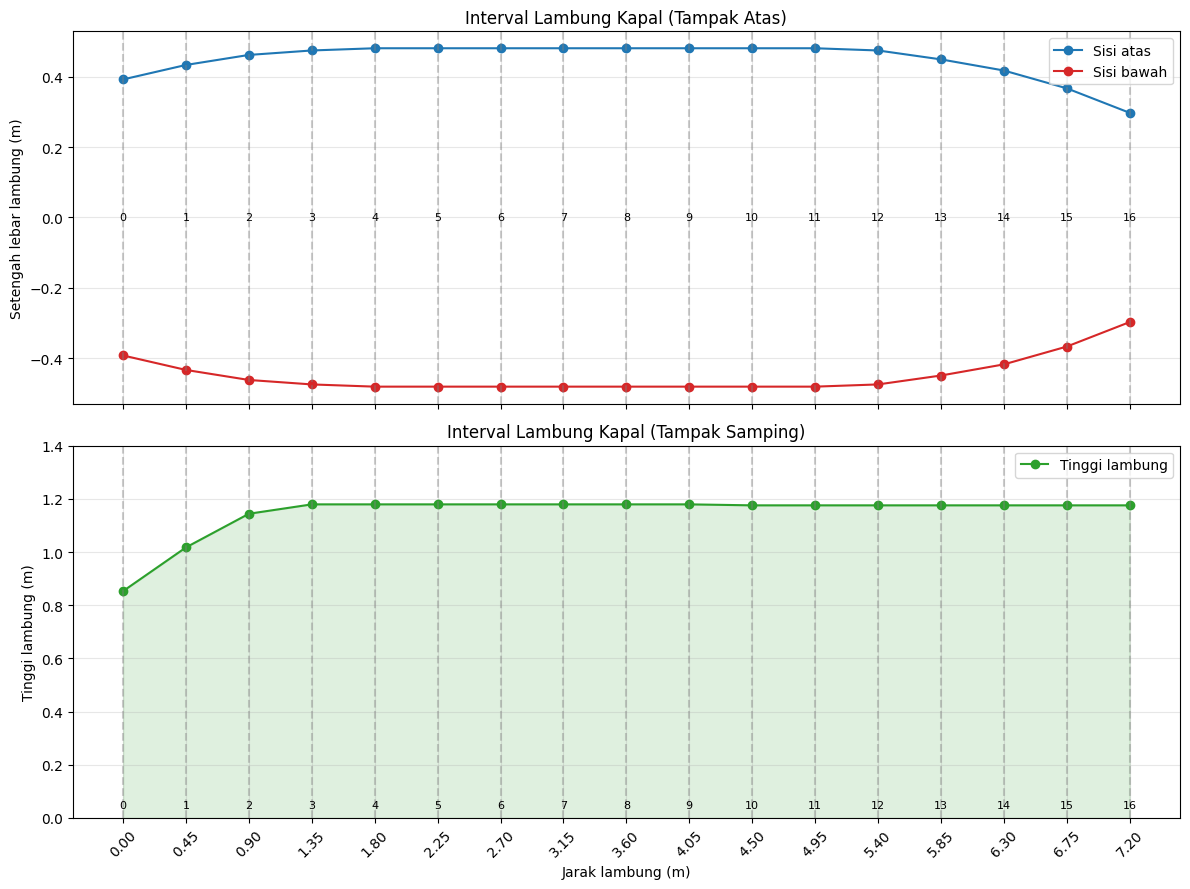

In [45]:
# jarak antar titik
h = 0.45
lebar = np.array([0.7840, 0.8662, 0.9231, 0.9484, 0.9610, 0.9610, 0.9610, 0.9610, 0.9610,
                  0.9610, 0.9610, 0.9610, 0.9484, 0.8978, 0.8346, 0.7334, 0.5943])
tinggi = np.array([0.8534, 1.0178, 1.1443, 1.1796, 1.1796, 1.1796, 1.1796, 1.1796, 1.1796,
                   1.1796, 1.1759, 1.1759, 1.1759, 1.1759, 1.1759, 1.1759, 1.1759])
jarak = np.arange(len(lebar)) * h

def tambah_interval(ax, y_label):
  for i, xi in enumerate(jarak):
        ax.axvline(xi, color="gray", ls="--", alpha=0.4)
        ax.text(xi, y_label, str(i), ha="center", va="center", fontsize=8)
# plot
fig, (ax_atas, ax_samping) = plt.subplots(2, 1, figsize=(12, 9), sharex=True)

# tampak atas
ax_atas.plot(jarak, lebar / 2, "o-", color="tab:blue", label="Sisi atas")
ax_atas.plot(jarak, -lebar / 2, "o-", color="tab:red", label="Sisi bawah")
tambah_interval(ax_atas, y_label=0)
ax_atas.set(title="Interval Lambung Kapal (Tampak Atas)",
            ylabel="Setengah lebar lambung (m)")

# tampak samping
ax_samping.plot(jarak, tinggi, "o-", color="tab:green", label="Tinggi lambung")
ax_samping.fill_between(jarak, 0, tinggi, color="tab:green", alpha=0.15)
tambah_interval(ax_samping, y_label=0.05)
ax_samping.set(title="Interval Lambung Kapal (Tampak Samping)",
               xlabel="Jarak lambung (m)",
               ylabel="Tinggi lambung (m)",
               ylim=(0, 1.4),
               xticks=jarak)
ax_samping.set_xticklabels([f"{v:.2f}" for v in jarak], rotation=45)

# hasil
for ax in (ax_atas, ax_samping):
  ax.grid(alpha = 0.3)
  ax.legend()

plt.tight_layout()
plt.show()

Rumus Luas Penampang:
$$
A_i = b_i \times h_i
$$

Keterangan:
- $A_i$ = luas penampang pada titik ke-$i$ ($m^2$)
- $b_i$ = lebar lambung pada titik ke-$i$ (m)
- $h_i$ = tinggi lambung pada titik ke-$i$ (m)

In [3]:
# hitung luas penampang
luas = lebar * tinggi

# hasil
hasil_tinggi_atas = pd.DataFrame({
    "Titik Grid": kotak,
    "Jarak (m)": jarak_m,
    "Lebar w (m)": lebar,
    "Tinggi t (m)": tinggi,
    "Luas Penampang (m2)": luas
})
hasil_tinggi_atas = hasil_tinggi_atas.round(4)
hasil_tinggi_atas

,Titik Grid,Jarak (m),Lebar w (m),Tinggi t (m),Luas Penampang (m2)
0,2,0.00,0.7840,0.8534,0.6691
1,3,0.45,0.8662,1.0178,0.8816
2,4,0.90,0.9231,1.1443,1.0563
3,5,1.35,0.9484,1.1796,1.1187
4,6,1.80,0.9610,1.1796,1.1336
5,7,2.25,0.9610,1.1796,1.1336
6,8,2.70,0.9610,1.1796,1.1336
7,9,3.15,0.9610,1.1796,1.1336
8,10,3.60,0.9610,1.1796,1.1336
9,11,4.05,0.9610,1.1796,1.1336


**Memeriksa jumlah titik dan interval**

Jumlah titik adalah 17 titik, sehingga intervalnya adalah 16 titik. Jika jumlah interval genap maka metode Simspon 1/3 dapat digunakan untuk perhitungan.

$$
n = N - 1
$$

$$
n = 17 - 1 = 16
$$

Jumlah interval adalah bilangan genap, maka syarat interval metode Simpson 1/3 terpenuhi

In [9]:
#hasil
print("Jumlah titik station =", len(kotak))
print("Jumlah interval atas =", len(kotak) - 1)
print("Jarak antar titik (h) =", h, "m")
print("Apakah syarat Simpson terpenuhi?  =", len(kotak))

assert len(kotak) == len(lebar) == len(tinggi) == 17
assert (len(kotak - 1)) % 2

Jumlah titik station = 17
Jumlah interval atas = 16
Jarak antar titik (h) = 0.45 m
Apakah syarat Simpson terpenuhi?  = 17


**Hitung Volume Kedua Lambung Kapal**

**Rumus Aturan Simpson 1/3 Komposit**
$$
V \approx \frac{h}{3}\left[A_0 + A_n + 4\sum_{i\text{ ganjil}} A_i + 2\sum_{i\text{ genap}} A_i\right]
$$

Keterangan:

* $V$ = Volume satu lambung kapal ($\text{m}^3$)
* $h$ = Jarak antar-titik pengukuran ($0{,}45\text{ m}$)
* $A_0$ = Luas penampang pada titik pertama ($i = 0$)
* $A_n$ = Luas penampang pada titik terakhir ($i = n = 16$)
* $\sum A_{i \text{ ganjil}}$ = Jumlah luas penampang untuk indeks bagian dalam bernilai ganjil ($i = 1, 3, 5, \dots, 15$), dikali **4**.
* $\sum A_{i \text{ genap}}$ = Jumlah luas penampang untuk indeks bagian dalam bernilai genap ($i = 2, 4, 6, \dots, 14$), dikali **2**



**Rumus Aturan Trapesium Komposit**
$$
V \approx \frac{h}{2}
\left[
A_0 + A_n + 2\sum_{i=1}^{n-1} A_i
\right]
$$

Keterangan:
- $V$ = volume satu lambung kapal ($m^3$)
- $h$ = jarak antar-titik (m)
- $A_i$ = luas penampang pada titik ke-$i$ ($m^2$)
- $A_0$ dan $A_n$ = luas penampang di titik awal dan akhir

**Perhitungan kedua volume lambung perahu**

$$
V_{\text{dua lambung}} = 2V_{\text{satu lambung}}
$$

In [4]:
# nilai array luas penampang
luas = hasil_tinggi_atas["Luas Penampang (m2)"].values

# Metode Simpson 1/3 Komposit
volume_satu_lambung_simpson = simpson(luas, dx=h)
volume_kedua_lambung_simpson = 2 * volume_satu_lambung_simpson

# Trapesium Komposit
try:
    trapz_fn = getattr(np, "trapezoid")
except AttributeError:
    trapz_fn = np.trapz
volume_trapesium = trapz_fn(luas, x=jarak_m)
volume_kedua_trapesium = 2 * volume_trapesium

# Hitung selisih kedua metode
selisih = abs(volume_kedua_lambung_simpson - volume_kedua_trapesium) / volume_kedua_lambung_simpson * 100

print(f"Volume satu lambung (Simpson 1/3) : {volume_satu_lambung_simpson:.4f} m³")
print(f"Volume kedua lambung (Simpson 1/3) : {volume_kedua_lambung_simpson:.4f} m³")
print(f"Volume satu lambung (Trapesium)   : {volume_trapesium:.4f} m³")
print(f"Volume kedua lambung (Trapesium)   : {volume_kedua_trapesium:.4f} m³")


Volume satu lambung (Simpson 1/3) : 7.5798 m³
Volume kedua lambung (Simpson 1/3) : 15.1596 m³
Volume satu lambung (Trapesium)   : 7.5676 m³
Volume kedua lambung (Trapesium)   : 15.1352 m³


**Hasil Perbandingan Antara kedua Aturan**

In [5]:
hasil_akhir = pd.DataFrame({
    "Aturan": ["Simpson 1/3", "Trapesium"],
    "Volume 1 Lambung (m3)": [volume_satu_lambung_simpson, volume_trapesium],
    "Volume 2 Lambung (m3)": [volume_kedua_lambung_simpson, volume_kedua_trapesium],
    "Volume 1 Lambung (liter)": [volume_satu_lambung_simpson * 1000, volume_trapesium * 1000],
    "Volume 2 Lambung (liter)": [volume_kedua_lambung_simpson * 1000, volume_kedua_trapesium * 1000]
})

hasil_akhir = hasil_akhir.round(4)
hasil_akhir

,Aturan,Volume 1 Lambung (m3),Volume 2 Lambung (m3),Volume 1 Lambung (liter),Volume 2 Lambung (liter)
0,Simpson 1/3,7.5798,15.1596,7579.8150,15159.630
1,Trapesium,7.5676,15.1352,7567.5825,15135.165


**Kesimpulan**

Dari hasil perhitungan, volume satu lambung kapal tanpa reserve buoyancy adalah dengan metode Simpson 1/3 sebesar 7,5798 m³ dan metode trapesium sebesar 7,5676 m³ . Karena kedua lambung dianggap memiliki ukuran yang sama, volume totalnya menjadi 15,1596 m³ (15.159,63 liter) untuk Simpson 1/3 dan 15,1352 m³ (15.135,17 liter) untuk metode trapesium.

Selisih hasil kedua metode sekitar 0,16 %, sehingga nilai volume yang diperoleh relatif berdekatan.
Metode Simpson 1/3 menghasilkan volume sedikit lebih besar dibandingkan metode trapesium. Metode Simpson 1/3 memiliki orde galat pemotongan yang lebih tinggi, yaitu $(O(\Delta x^4))$, dibandingkan metode trapesium yang berorde $(O(\Delta x^2))$.

Perhitungan dilakukan menggunakan rumus luas penampang $(A(x)=lebar(x)\times tinggi(x))$, sehingga setiap penampang dianggap berbentuk persegi panjang dengan lantai kapal yang datar.
Asumsi digunakan untuk menyederhanakan perhitungan volume berdasarkan data lebar dan tinggi.




